**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5061 - Operaciones de aprendizaje automático**

Tecnológico de Monterrey

Prof. Iván Reyes Amezcua

**Semana 5**
Proyecto MiBici: propuesta y base reproducible

---

* NOMBRE:
  * Jimena María Suárez Muñoz
  * Jesús Carrillo Cantú
  * Oscar Alfonso Valenzuela Muñoz
  * Luis Antonio Cárdenas Trejo

* MATRÍCULA:
  * A01652504
  * A01840421
  * A01840486
  * A01840592

In [ ]:
# Importación de librerías
import sys
from pathlib import Path

# Detectar raiz del proyecto buscando pyproject.toml como marcador
def find_proj_root(start: Path, marker="pyproject.toml") -> Path:
    for parent in [start, *start.parents]:
        if (parent / marker).exists():
            return parent
    raise FileNotFoundError(f"No se encontro {marker} desde {start}")

PROJ_ROOT = find_proj_root(Path(".").resolve())
print(f"PROJ_ROOT: {PROJ_ROOT}")
sys.path.insert(0, str(PROJ_ROOT))

from mi_bici.config import RAW_DATA_DIR
print(f"RAW_DATA_DIR: {RAW_DATA_DIR}")


import mlflow
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import mean_absolute_error, classification_report, f1_score, silhouette_score
from sklearn.cluster import KMeans

# Estilo de gráficas
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 5)

import warnings
warnings.filterwarnings('ignore')

# Columnas canonicas de los archivos de viajes
TRIPS_COLS = [
    "Viaje_Id", "Usuario_Id", "Genero", "Anio_de_nacimiento",
    "Inicio_del_viaje", "Fin_del_viaje", "Origen_Id", "Destino_Id"
]

# Helper: leer CSV con auto-deteccion de encoding y normalizacion de columnas
# Los archivos de MiBici mezclan latin-1 (2024) y utf-8 (2026+),
# y algunos headers estan corruptos en el archivo fuente.
def read_csv_auto(path, canonical_cols=None, **kwargs):
    for enc in ["utf-8", "latin-1"]:
        try:
            df = pd.read_csv(path, encoding=enc, **kwargs)
            if canonical_cols and len(df.columns) == len(canonical_cols):
                df.columns = canonical_cols
            return df
        except UnicodeDecodeError:
            continue
    raise ValueError(f"No se pudo leer {path} con utf-8 ni latin-1")


2026-10-18 15:05:00.649 | INFO     | mi_bici.config:<module>:11 - PROJ_ROOT path is: /Users/lact/Documents/mlops-projects/mi-bici/TC5061-Proyecto-Equipo11


PROJ_ROOT: /Users/lact/Documents/mlops-projects/mi-bici/TC5061-Proyecto-Equipo11
RAW_DATA_DIR: /Users/lact/Documents/mlops-projects/mi-bici/TC5061-Proyecto-Equipo11/data/raw


In [2]:
# Cargamos nomenclatura
stations_path = RAW_DATA_DIR / "stations" / "nomenclatura_2026_09.csv"
stations_df = read_csv_auto(stations_path)
print("Registros")
print(stations_df)
print("Informacion del dataset")
print(stations_df.info())



Registros
      id                                           name   latitude  \
0      2  (GDL-001) C. Epigmenio Glez./ Av. 16 de Sept.  20.666378   
1      3     (GDL-002) C. Colonias  / Av.  Niños héroes  20.667228   
2      4          (GDL-003) C. Vidrio / Av. Chapultepec  20.667690   
3      5           (GDL-004) C. Ghilardi /C. Miraflores  20.691847   
4      6  (GDL-005) C. San Diego /Calzada Independencia  20.681158   
..   ...                                            ...        ...   
479  515    (GDL-295) C. Tarahumaras / Av. Manuel Acuña  20.684117   
480  516    (ZPN-105) Av. Atemajac/Colinas del Congreso  20.721205   
481  517   (ZPN-106) Av. Atemajac/Colinas del Capitolio  20.720910   
482  518     (ZPN-108) Av. Atemajac / Av. Yermo y Parra  20.721377   
483  519    (ZPN-107) C. Colina Aria / Av. Díaz de León  20.719219   

      longitude  dpcapacity  
0   -103.348820          15  
1   -103.366000          15  
2   -103.368252          19  
3   -103.362549          19  

In [3]:
# Cargar todos los archivos de viajes en raw/trips/
trips_dir = RAW_DATA_DIR / "trips"
trips_files = sorted(trips_dir.glob("datos_abiertos_*.csv"))

print(f"Archivos encontrados: {len(trips_files)}")
for f in trips_files:
    print(f"  {f.name}")

# read_csv_auto detecta encoding y normaliza columnas corruptas
travels_df = pd.concat(
    [read_csv_auto(f, canonical_cols=TRIPS_COLS) for f in trips_files],
    ignore_index=True
)

print(f"Registros totales: {travels_df.shape}")
print(f"Columnas: {list(travels_df.columns)}")



Archivos encontrados: 33
  datos_abiertos_2024_01.csv
  datos_abiertos_2024_02.csv
  datos_abiertos_2024_03.csv
  datos_abiertos_2024_04.csv
  datos_abiertos_2024_05.csv
  datos_abiertos_2024_06.csv
  datos_abiertos_2024_07.csv
  datos_abiertos_2024_08.csv
  datos_abiertos_2024_09.csv
  datos_abiertos_2024_10.csv
  datos_abiertos_2024_11.csv
  datos_abiertos_2024_12.csv
  datos_abiertos_2025_01.csv
  datos_abiertos_2025_02.csv
  datos_abiertos_2025_03.csv
  datos_abiertos_2025_04.csv
  datos_abiertos_2025_05.csv
  datos_abiertos_2025_06.csv
  datos_abiertos_2025_07.csv
  datos_abiertos_2025_08.csv
  datos_abiertos_2025_09.csv
  datos_abiertos_2025_10.csv
  datos_abiertos_2025_11.csv
  datos_abiertos_2025_12.csv
  datos_abiertos_2026_01.csv
  datos_abiertos_2026_02.csv
  datos_abiertos_2026_03.csv
  datos_abiertos_2026_04.csv
  datos_abiertos_2026_05.csv
  datos_abiertos_2026_06.csv
  datos_abiertos_2026_07.csv
  datos_abiertos_2026_08.csv
  datos_abiertos_2026_09.csv
Registros totales:

In [4]:
# Imprimimos el Dataframe unificado
print(travels_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12540018 entries, 0 to 12540017
Data columns (total 8 columns):
 #   Column              Dtype  
---  ------              -----  
 0   Viaje_Id            int64  
 1   Usuario_Id          int64  
 2   Genero              object 
 3   Anio_de_nacimiento  float64
 4   Inicio_del_viaje    object 
 5   Fin_del_viaje       object 
 6   Origen_Id           int64  
 7   Destino_Id          int64  
dtypes: float64(1), int64(4), object(3)
memory usage: 765.4+ MB
None


In [5]:
travels_df

,Viaje_Id,Usuario_Id,Genero,Anio_de_nacimiento,Inicio_del_viaje,Fin_del_viaje,Origen_Id,Destino_Id
0,31789291,640715,M,1984.0,2024-01-01 00:05:25,2024-01-01 00:29:37,294,271
1,31789292,2353010,F,1995.0,2024-01-01 00:07:23,2024-01-01 00:16:37,182,254
2,31789293,1556365,M,1984.0,2024-01-01 00:07:31,2024-01-01 00:16:37,182,254
3,31789294,2626233,M,1994.0,2024-01-01 00:07:56,2024-01-01 00:31:51,35,154
4,31789295,2602006,M,1998.0,2024-01-01 00:08:09,2024-01-01 00:31:51,35,154
...,...,...,...,...,...,...,...,...
12540013,46255554,116275,F,1990.0,2026-09-30 23:57:23,2026-09-30 23:59:46,43,44
12540014,46255556,4621160,M,1970.0,2026-09-30 23:59:13,2026-10-01 00:04:17,210,413
12540015,46255556,4621160,M,1970.0,2026-09-30 23:59:13,2026-10-01 00:04:17,210,413
12540016,46255557,4560372,M,1987.0,2026-09-30 23:59:32,2026-10-01 00:06:16,157,271


In [6]:
# Obtener las estadisticas descriptivas
num_cols = travels_df.select_dtypes(include=[np.number]).columns
print("Descriptivas para Columnas numericas")
print(num_cols)

#Para las numéricas, incluye el sesgo y la curtosis.
descriptivas_num = travels_df[num_cols].describe().T
#Simetria
simetria = travels_df[num_cols].skew(numeric_only=True).T
#Curtosis
curtosis = travels_df[num_cols].kurtosis(numeric_only=True).T
#Cambiamos nombre del indice y asignamos valores
descriptivas_num['skewness'] = simetria
descriptivas_num['kurtosis'] = curtosis
display(descriptivas_num)


Descriptivas para Columnas numericas
Index(['Viaje_Id', 'Usuario_Id', 'Anio_de_nacimiento', 'Origen_Id',
       'Destino_Id'],
      dtype='object')


,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis
Viaje_Id,12540018.0,3.902680e+07,4.167696e+06,31789291.0,35439800.25,39025612.5,42607772.75,46255558.0,2.393726e-09,-3.000001
Usuario_Id,12540018.0,2.291789e+06,1.657692e+06,102.0,614716.00,2213654.0,4047230.00,5006315.0,1.180743e-09,-3.000001
Anio_de_nacimiento,12535915.0,1.990210e+03,1.581874e+01,199.0,1985.00,1993.0,1998.00,2023.0,NaN,-3.000001
Origen_Id,12540018.0,1.567623e+02,1.148149e+02,2.0,51.00,157.0,257.00,519.0,1.219339e-03,-3.000001
Destino_Id,12540018.0,1.584789e+02,1.176408e+02,2.0,51.00,156.0,261.00,519.0,1.187717e-03,-3.000001


In [7]:
# Obtener descriptivas categoricas
cat_cols = travels_df.select_dtypes(include=["object"]).columns.tolist()
print("Descriptivas para Columnas categoricas")
print(cat_cols)

# pandas 3.x tiene un bug con value_counts() en DataFrames concatenados grandes.
# Se calculan las estadísticas directamente con numpy como workaround.
def describe_categorical_np(df, cols):
    rows = []
    for col in cols:
        arr = df[col].to_numpy()
        non_null = arr[
            [x is not None and not (isinstance(x, float) and np.isnan(x)) for x in arr]
        ]
        unique_vals, counts = np.unique(non_null, return_counts=True)
        top_idx = np.argmax(counts) if len(counts) > 0 else None
        rows.append({
            "column": col,
            "count": len(non_null),
            "unique": len(unique_vals),
            "top": unique_vals[top_idx] if top_idx is not None else None,
            "freq": int(counts[top_idx]) if top_idx is not None else None,
            "missing": len(arr) - len(non_null),
            "missing_pct": round((len(arr) - len(non_null)) / len(arr) * 100, 2),
        })
    return pd.DataFrame(rows).set_index("column")

desc_cat = describe_categorical_np(travels_df, cat_cols)
display(desc_cat)


Descriptivas para Columnas categoricas
['Genero', 'Inicio_del_viaje', 'Fin_del_viaje']


,count,unique,top,freq,missing,missing_pct
column,,,,,,
Genero,12448329,2,M,9038680,91689,0.73
Inicio_del_viaje,12540018,10480674,28/10/2024 18:08,60,0,0.00
Fin_del_viaje,12540018,10492938,24/09/2024 18:21,49,0,0.00


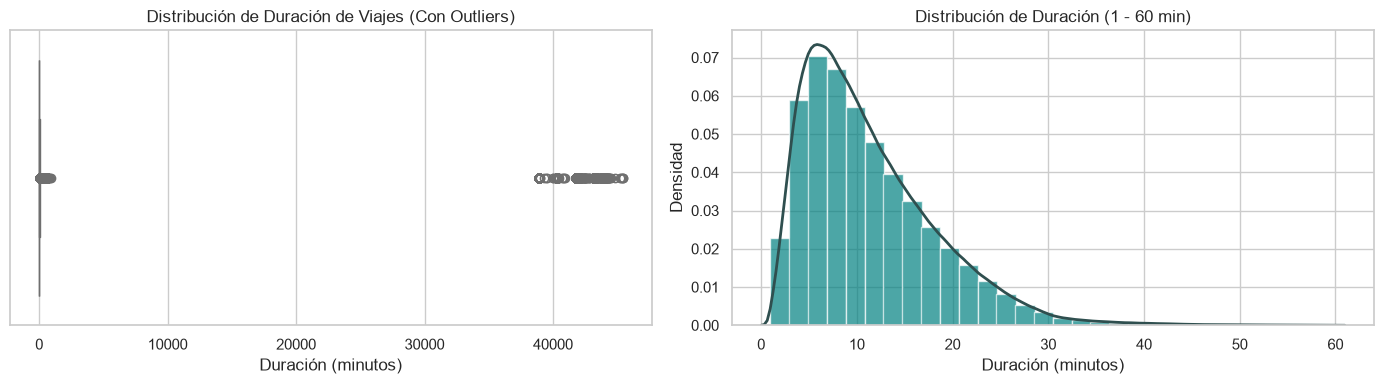

In [8]:
# 1. Conversión de fechas e ingeniería preliminar
travels_df['Inicio_del_viaje'] = pd.to_datetime(travels_df['Inicio_del_viaje'], errors='coerce', dayfirst=True)
travels_df['Fin_del_viaje'] = pd.to_datetime(travels_df['Fin_del_viaje'], errors='coerce', dayfirst=True)

# 2. Eliminar registros con fechas inválidas (NaT)
travels_df = travels_df.dropna(subset=['Inicio_del_viaje', 'Fin_del_viaje']).copy()

# 3. Extracción de características temporales
travels_df['fecha'] = travels_df['Inicio_del_viaje'].dt.date
travels_df['hora'] = travels_df['Inicio_del_viaje'].dt.hour
travels_df['dia_semana'] = travels_df['Inicio_del_viaje'].dt.dayofweek
travels_df['es_fin_semana'] = travels_df['dia_semana'].isin([5, 6]).astype(int)
travels_df['duracion_min'] = (travels_df['Fin_del_viaje'] - travels_df['Inicio_del_viaje']).dt.total_seconds() / 60.0

# 4. Visualización
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# 4.1. Boxplot (Seaborn)
sns.boxplot(x=travels_df['duracion_min'], ax=axes[0], color='skyblue')
axes[0].set_title('Distribución de Duración de Viajes (Con Outliers)')
axes[0].set_xlabel('Duración (minutos)')

# 4.2. Subconjunto (1 a 60 minutos)
sub_travels = travels_df[travels_df['duracion_min'].between(1, 60)]

# 4.3. Histograma manual usando pd.cut (Evita el bug de np.histogram en Python 3.14)
binned_counts, bin_edges = pd.cut(sub_travels['duracion_min'], bins=30, retbins=True)
bin_counts = binned_counts.value_counts(sort=False)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
bin_width = bin_edges[1] - bin_edges[0]

# Normalización de densidad
density = bin_counts / (bin_counts.sum() * bin_width)

# Dibujar barras con Matplotlib bar
axes[1].bar(bin_centers, density, width=bin_width, color='teal', edgecolor='white', alpha=0.7)

# Curva KDE sobrepuesta (Seaborn)
sns.kdeplot(data=sub_travels, x='duracion_min', ax=axes[1], color='darkslategrey', linewidth=2)

axes[1].set_title('Distribución de Duración (1 - 60 min)')
axes[1].set_xlabel('Duración (minutos)')
axes[1].set_ylabel('Densidad')

plt.tight_layout()
plt.show()

In [9]:
# Conversión de fechas especificando día primero
travels_df['Inicio_del_viaje'] = pd.to_datetime(travels_df['Inicio_del_viaje'], errors='coerce', dayfirst=True)
travels_df['Fin_del_viaje'] = pd.to_datetime(travels_df['Fin_del_viaje'], errors='coerce', dayfirst=True)

# Eliminar solo filas que realmente contengan fechas nulas
travels_df = travels_df.dropna(subset=['Inicio_del_viaje', 'Fin_del_viaje']).copy()

# Extracción de variables temporales
travels_df['hora'] = travels_df['Inicio_del_viaje'].dt.hour
travels_df['dia_semana'] = travels_df['Inicio_del_viaje'].dt.dayofweek
travels_df['es_fin_semana'] = travels_df['dia_semana'].isin([5, 6]).astype(int)

# Verifica que el conteo no sea cero
print(f"Total de viajes cargados correctamente: {len(travels_df)}")

Total de viajes cargados correctamente: 4615530


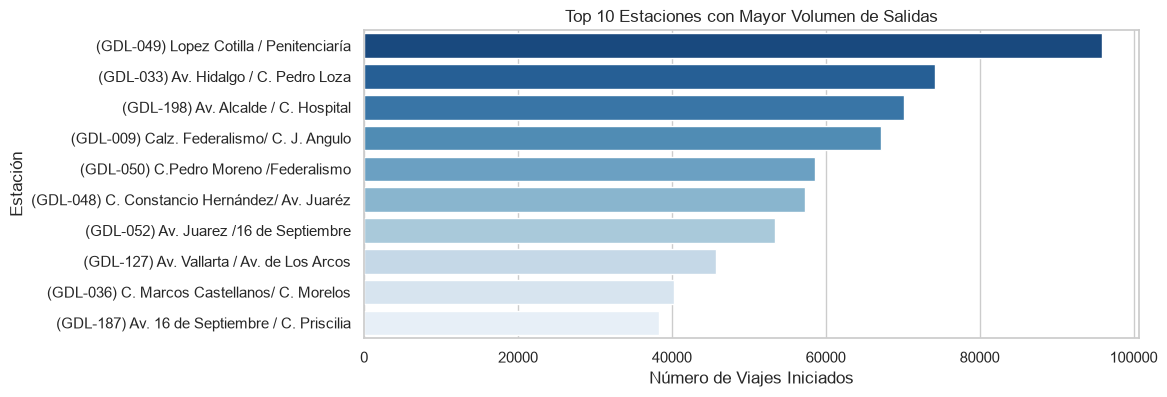

In [10]:
# 4.3. Análisis Estacional y Top Estaciones
top_origen = travels_df['Origen_Id'].value_counts().head(10).reset_index()
top_origen.columns = ['Origen_Id', 'conteo_salidas']
top_origen = top_origen.merge(stations_df, left_on='Origen_Id', right_on='id', how='left')

plt.figure(figsize=(10, 4))
sns.barplot(data=top_origen, x='conteo_salidas', y='name', palette='Blues_r')
plt.title('Top 10 Estaciones con Mayor Volumen de Salidas')
plt.xlabel('Número de Viajes Iniciados')
plt.ylabel('Estación')
plt.show()

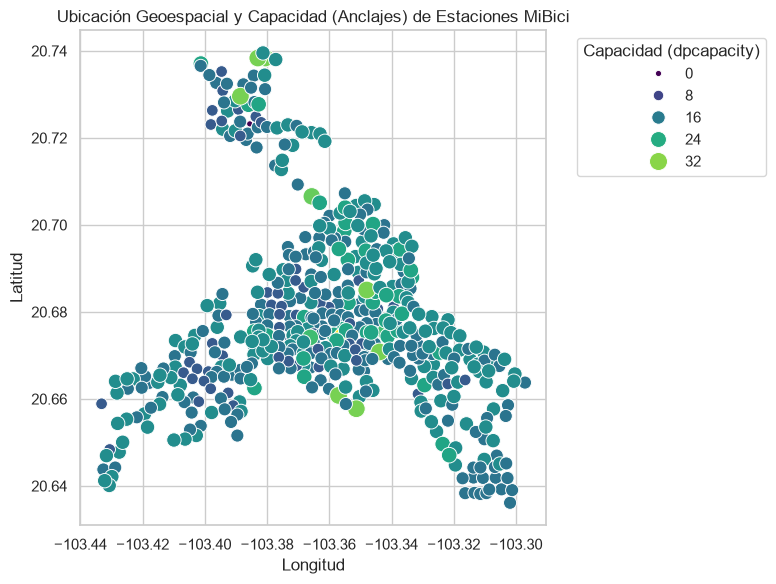

In [11]:
# 4.4. Distribución Geoespacial de Estaciones y Capacidad
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=stations_df,
    x='longitude',
    y='latitude',
    size='dpcapacity',
    hue='dpcapacity',
    palette='viridis',
    sizes=(20, 200)
)
plt.title('Ubicación Geoespacial y Capacidad (Anclajes) de Estaciones MiBici')
plt.xlabel('Longitud')
plt.ylabel('Latitud')
plt.legend(title='Capacidad (dpcapacity)', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [12]:
# Filtrado definitivo de duraciones anómalas (menores a 1 min o mayores a 24h)
viajes_clean = travels_df[(travels_df['duracion_min'] >= 1) & (travels_df['duracion_min'] <= 1440)].copy()
print(f"Viajes limpios para modelado: {len(viajes_clean)}")

Viajes limpios para modelado: 4460968


Pregunta 1

### **P1: Predicción de Demanda de Viajes (Regresión)**
* **Objetivo de negocio:** Predecir cuántos viajes se iniciarán en cada estación por hora para facilitar la planificación de la flota por el operador del sistema.
* **Modelo:** Bosque Aleatorio Regresor optimizado con búsqueda de hiperparámetros por validación cruzada temporal (`TimeSeriesSplit`).

In [13]:
# Agregación por hora y estación para estructurar la serie temporal
demanda_df = viajes_clean.groupby(['fecha', 'hora', 'Origen_Id']).size().reset_index(name='total_viajes')

# Unir con información estática de la estación
demanda_df = demanda_df.merge(stations_df, left_on='Origen_Id', right_on='id', how='left')
demanda_df.drop(columns=['id'], errors='ignore', inplace=True)

# Ordenar cronológicamente
demanda_df['fecha'] = pd.to_datetime(demanda_df['fecha'])
demanda_df['dia_semana'] = demanda_df['fecha'].dt.dayofweek
demanda_df = demanda_df.sort_values(['fecha', 'hora']).reset_index(drop=True)

# Definir X e y
features_p1 = ['hora', 'dia_semana', 'Origen_Id', 'latitude', 'longitude', 'dpcapacity']
X_p1 = demanda_df[features_p1].fillna(0)
y_p1 = demanda_df['total_viajes']

# Split Cronológico: 80% Train+Val / 20% Test Retenido
corte_idx = int(len(demanda_df) * 0.80)
X_train_val, X_test = X_p1.iloc[:corte_idx], X_p1.iloc[corte_idx:]
y_train_val, y_test = y_p1.iloc[:corte_idx], y_p1.iloc[corte_idx:]

print(f"Train/Val size: {len(X_train_val)} | Test size: {len(X_test)}")

# Configuración de TimeSeriesSplit y GridSearchCV
tscv = TimeSeriesSplit(n_splits=5)
param_grid = {
    'n_estimators': [30, 50],
    'max_depth': [5, 10],
    'min_samples_split': [2, 5]
}

rf_p1 = RandomForestRegressor(random_state=42)
grid_search_p1 = GridSearchCV(
    estimator=rf_p1,
    param_grid=param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

grid_search_p1.fit(X_train_val, y_train_val)

print("\n--- Resultados P1 ---")
print(f"Mejores Hiperparámetros: {grid_search_p1.best_params_}")
print(f"Mejor MAE en Validación Cruzada (TSC): {-grid_search_p1.best_score_:.3f}")

# Evaluación en conjunto Test retenido
mejor_rf_p1 = grid_search_p1.best_estimator_
y_pred_p1 = mejor_rf_p1.predict(X_test)

baseline_pred_p1 = np.full(shape=y_test.shape, fill_value=y_train_val.median())
print(f"MAE Baseline (Mediana) en Test: {mean_absolute_error(y_test, baseline_pred_p1):.3f}")
print(f"MAE Modelo Optimizado en Test: {mean_absolute_error(y_test, y_pred_p1):.3f}")

Train/Val size: 1236423 | Test size: 309106

--- Resultados P1 ---
Mejores Hiperparámetros: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 50}
Mejor MAE en Validación Cruzada (TSC): 1.419
MAE Baseline (Mediana) en Test: 1.583
MAE Modelo Optimizado en Test: 1.378


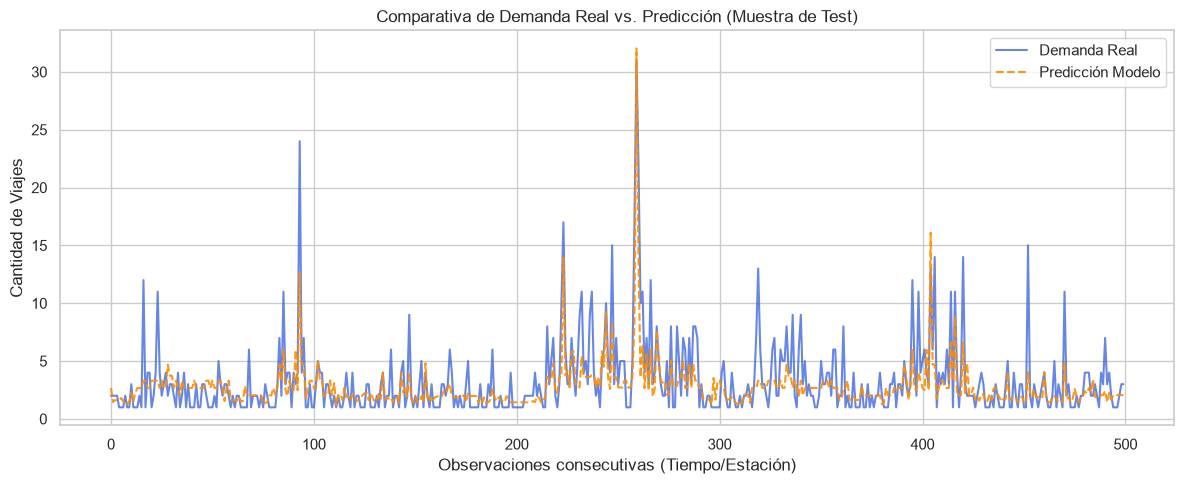

In [14]:
# Visualización de Predicciones vs Valores Reales para P1 (Muestra de Test)
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 5))
slt_idx = 500  # Tomar una pequeña muestra consecutiva de test para evaluar visualmente la serie temporal
plt.plot(y_test.values[:slt_idx], label='Demanda Real', color='royalblue', alpha=0.8)
plt.plot(y_pred_p1[:slt_idx], label='Predicción Modelo', color='darkorange', linestyle='--', alpha=0.9)
plt.title('Comparativa de Demanda Real vs. Predicción (Muestra de Test)')
plt.xlabel('Observaciones consecutivas (Tiempo/Estación)')
plt.ylabel('Cantidad de Viajes')
plt.legend()
plt.tight_layout()
plt.show()

Pregunta 2

### **P2: Clasificación de Riesgo de Desabasto**
* **Objetivo de negocio:** Identificar si una estación estará en riesgo de quedarse desabastecida (definido aquí como una demanda estimada que supera el 70% de su capacidad instalada de anclajes) para alertar al equipo de rebalanceo.
* **Modelo:** Bosque Aleatorio Clasificador.

In [15]:
# Definir un umbral de alto uso (ej. demandas que superan el 70% de la capacidad de la estación)
demanda_df['riesgo_desabasto'] = (demanda_df['total_viajes'] >= 0.7 * demanda_df['dpcapacity']).astype(int)

y_p2 = demanda_df['riesgo_desabasto']
y_train_val_p2, y_test_p2 = y_p2.iloc[:corte_idx], y_p2.iloc[corte_idx:]

# Entrenar modelo de Clasificación
rf_p2 = RandomForestClassifier(n_estimators=50, max_depth=8, random_state=42)
rf_p2.fit(X_train_val, y_train_val_p2)

y_pred_p2 = rf_p2.predict(X_test)

print("--- Resultados P2 (Clasificación) ---")
print(f"F1-Score: {f1_score(y_test_p2, y_pred_p2, zero_division=0):.3f}")
print("\nReporte de Clasificación:")
print(classification_report(y_test_p2, y_pred_p2, zero_division=0))

--- Resultados P2 (Clasificación) ---
F1-Score: 0.248

Reporte de Clasificación:
              precision    recall  f1-score   support

           0       0.99      1.00      1.00    305663
           1       0.80      0.15      0.25      3443

    accuracy                           0.99    309106
   macro avg       0.90      0.57      0.62    309106
weighted avg       0.99      0.99      0.99    309106



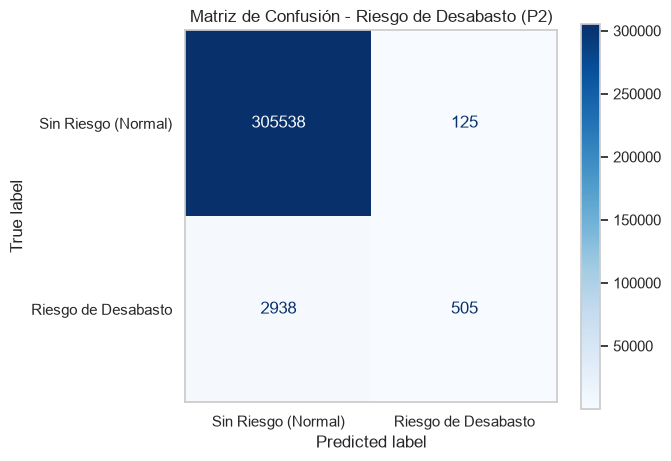

In [16]:
# Matriz de Confusión para el modelo de Clasificación de Riesgo
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_p2, y_pred_p2)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Sin Riesgo (Normal)', 'Riesgo de Desabasto'])
fig, ax = plt.subplots(figsize=(6, 5))
disp.plot(cmap='Blues', ax=ax, values_format='d')
plt.title('Matriz de Confusión - Riesgo de Desabasto (P2)')
plt.grid(False)
plt.show()

Pregunta 3

### **P3: Segmentación y Patrones de Uso de Estaciones (Clustering)**
* **Objetivo de negocio:** Encontrar perfiles de comportamiento de uso por hora para definir la planeación urbana y futuras expansiones del sistema.
* **Modelo:** K-Means Clustering ($K=4$ clusters).

In [17]:
# Construir perfil de uso por estación (promedio de viajes por hora del día)
perfil_estaciones = demanda_df.pivot_table(
    index='Origen_Id',
    columns='hora',
    values='total_viajes',
    aggfunc='mean'
).fillna(0)

# Agrupamiento mediante KMeans
kmeans = KMeans(n_clusters=4, random_state=42)
perfil_estaciones['cluster'] = kmeans.fit_predict(perfil_estaciones)

# Evaluación del Silhouette Score
score_silhouette = silhouette_score(perfil_estaciones.drop(columns=['cluster']), perfil_estaciones['cluster'])
print(f"Silhouette Score para K=4: {score_silhouette:.3f}")

# Mostrar distribución de estaciones en clusters
print(perfil_estaciones['cluster'].value_counts())

Silhouette Score para K=4: 0.454
cluster
3    281
1    134
0     50
2      8
Name: count, dtype: int64


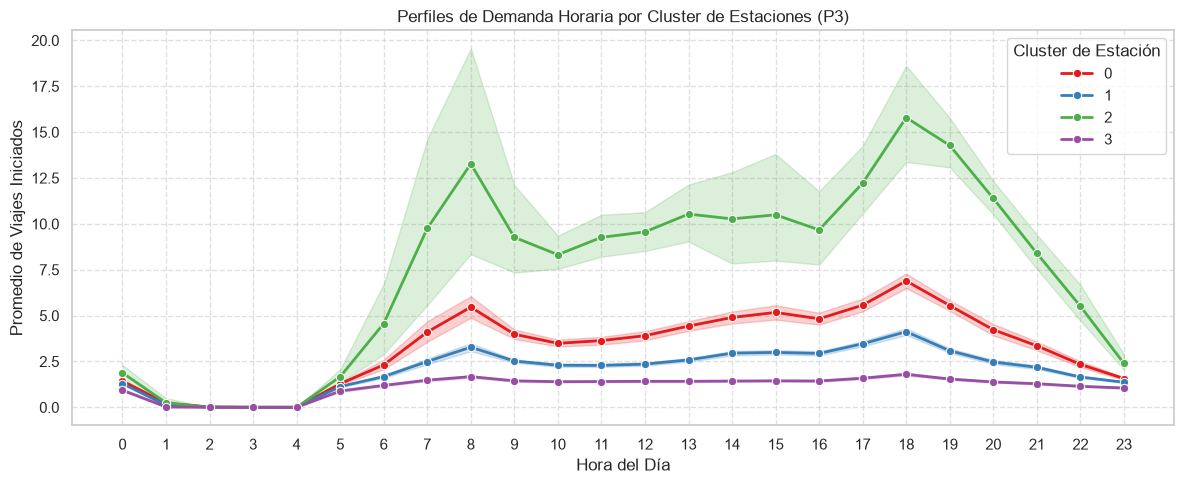

In [18]:
# Perfil promedio de viajes por hora para cada Cluster
perfil_melted = perfil_estaciones.melt(id_vars=['cluster'], var_name='hora', value_name='viajes_promedio')

plt.figure(figsize=(12, 5))
sns.lineplot(data=perfil_melted, x='hora', y='viajes_promedio', hue='cluster', palette='Set1', marker='o', linewidth=2)
plt.title('Perfiles de Demanda Horaria por Cluster de Estaciones (P3)')
plt.xlabel('Hora del Día')
plt.ylabel('Promedio de Viajes Iniciados')
plt.xticks(range(24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Cluster de Estación')
plt.tight_layout()
plt.show()

### **Registro y Tracking de Experimentos con MLflow**

A continuación, configuramos el servidor de tracking de MLflow, definimos el experimento `mibici-equipo11` y registramos de manera reproducible cada uno de los modelos y baselines correspondientes a **P1**, **P2** y **P3** junto con sus parámetros, métricas de desempeño, etiquetas identificadoras y artefactos gráficos.

In [ ]:
# Setup MLflow
mlflow.set_tracking_uri(uri="http://127.0.0.1:5001")
# Definir el nombre del experimento con el número de equipo
EXPERIMENT_NAME = "mibici-equipo11"
mlflow.set_experiment(EXPERIMENT_NAME)

# Metadatos comunes para reproducibilidad
GIT_COMMIT = "main-initial-baseline"
DATA_VERSION = "v1.0-2026-09"
FECHA_MIN = str(viajes_clean['Inicio_del_viaje'].min().date())
FECHA_MAX = str(viajes_clean['Inicio_del_viaje'].max().date())

COMMON_TAGS = {
    "equipo": "Equipo 11",
    "git.commit": GIT_COMMIT,
    "data.version": DATA_VERSION
}

print(f"Experimento configurado: {EXPERIMENT_NAME}")

2026/10/18 15:07:16 INFO mlflow.tracking.fluent: Experiment with name 'mibici-equipo11' does not exist. Creating a new experiment.


Experimento configurado: mibici-equipo11


In [20]:
# --- RUN PARA P1 (REGRESIÓN DE DEMANDA) ---
with mlflow.start_run(run_name="P1_Demanda_Regresor_Baseline") as run:
    # Registrar etiquetas del equipo y pregunta
    mlflow.set_tags({**COMMON_TAGS, "pregunta": "P1", "tipo_tarea": "Regresion"})

    # Registrar parámetros
    mlflow.log_params({
        "fecha_inicio": FECHA_MIN,
        "fecha_fin": FECHA_MAX,
        "test_size_pct": 0.20,
        "model_type": "RandomForestRegressor",
        "n_estimators": mejor_rf_p1.n_estimators,
        "max_depth": mejor_rf_p1.max_depth
    })

    # Registrar métricas
    mae_test = mean_absolute_error(y_test, y_pred_p1)
    mae_baseline = mean_absolute_error(y_test, baseline_pred_p1)
    mlflow.log_metric("mae_test", mae_test)
    mlflow.log_metric("mae_baseline_mediana", mae_baseline)

    # Guardar y registrar gráfica comparativa como artefacto
    fig_p1, ax = plt.subplots(figsize=(12, 5))
    ax.plot(y_test.values[:500], label='Demanda Real', color='royalblue')
    ax.plot(y_pred_p1[:500], label='Predicción Modelo', color='darkorange', linestyle='--')
    ax.set_title('P1: Comparativa Demanda Real vs. Predicción')
    ax.legend()
    fig_p1.savefig("p1_predicciones_vs_real.png")
    mlflow.log_artifact("p1_predicciones_vs_real.png")
    plt.close(fig_p1)

    print("Run para P1 registrado exitosamente en MLflow.")

Run para P1 registrado exitosamente en MLflow.
🏃 View run P1_Demanda_Regresor_Baseline at: http://127.0.0.1:5001/#/experiments/1/runs/519abcd1618c4f64a7215eeb49c67f4c
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


In [21]:
# --- RUN PARA P2 (CLASIFICACIÓN DE RIESGO DE DESABASTO) ---
with mlflow.start_run(run_name="P2_Riesgo_Clasificador_Baseline") as run:
    # Registrar etiquetas del equipo y pregunta
    mlflow.set_tags({**COMMON_TAGS, "pregunta": "P2", "tipo_tarea": "Clasificacion"})

    # Registrar parámetros
    mlflow.log_params({
        "fecha_inicio": FECHA_MIN,
        "fecha_fin": FECHA_MAX,
        "umbral_desabasto_capacidad_pct": 0.70,
        "model_type": "RandomForestClassifier",
        "n_estimators": 50,
        "max_depth": 8
    })

    # Registrar métricas
    f1 = f1_score(y_test_p2, y_pred_p2, zero_division=0)
    mlflow.log_metric("f1_score_test", f1)

    # Guardar y registrar matriz de confusión como artefacto
    fig_p2, ax = plt.subplots(figsize=(6, 5))
    cm = confusion_matrix(y_test_p2, y_pred_p2)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Sin Riesgo', 'Riesgo'])
    disp.plot(cmap='Blues', ax=ax, values_format='d')
    ax.set_title('P2: Matriz de Confusión - Riesgo de Desabasto')
    fig_p2.savefig("p2_matriz_confusion.png")
    mlflow.log_artifact("p2_matriz_confusion.png")
    plt.close(fig_p2)

    print("Run para P2 registrado exitosamente en MLflow.")

Run para P2 registrado exitosamente en MLflow.
🏃 View run P2_Riesgo_Clasificador_Baseline at: http://127.0.0.1:5001/#/experiments/1/runs/20c19bf0b8fb4dd99e0f53c236c83426
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1


In [22]:
# --- RUN PARA P3 (SEGMENTACIÓN DE ESTACIONES) ---
with mlflow.start_run(run_name="P3_Estaciones_Clustering_Baseline") as run:
    # Registrar etiquetas del equipo y pregunta
    mlflow.set_tags({**COMMON_TAGS, "pregunta": "P3", "tipo_tarea": "Clustering"})

    # Registrar parámetros
    mlflow.log_params({
        "model_type": "KMeans",
        "n_clusters": 4,
        "random_state": 42
    })

    # Registrar métricas
    mlflow.log_metric("silhouette_score", score_silhouette)

    # Guardar y registrar gráfica de perfiles de clusters como artefacto
    fig_p3, ax = plt.subplots(figsize=(12, 5))
    sns.lineplot(data=perfil_melted, x='hora', y='viajes_promedio', hue='cluster', palette='Set1', marker='o', ax=ax)
    ax.set_title('P3: Perfiles de Demanda Horaria por Cluster')
    fig_p3.savefig("p3_perfil_clusters.png")
    mlflow.log_artifact("p3_perfil_clusters.png")
    plt.close(fig_p3)

    print("Run para P3 registrado exitosamente en MLflow.")

Run para P3 registrado exitosamente en MLflow.
🏃 View run P3_Estaciones_Clustering_Baseline at: http://127.0.0.1:5001/#/experiments/1/runs/aff6a53bd8b946908b87e1258a23f7d0
🧪 View experiment at: http://127.0.0.1:5001/#/experiments/1
